# Allstate Claims Severity
## 01 — Data Understanding

### Objective
The goal of this project is to predict insurance claim severity
using historical claim data.

This is a supervised regression problem where `loss` represents
the target variable.

### In This Notebook
- Load and inspect the dataset.
- Explore feature types and dataset structure.
- Identify missing values and duplicate records.
- Examine the distribution of the target variable.
- Summarize initial observations and findings.

In [1]:
import sys

import numpy as np
import pandas as pd
import sklearn

print("Python path:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python path: /Users/ebrietas/Allstate_Claims_Severity/.venv/bin/python
Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1


## 1. Data Loading

Load the training and test datasets using Pandas.

The training dataset includes the target variable (`loss`),
while the test dataset is used for generating predictions.

We will first verify their dimensions and structure.

In [2]:
from pathlib import Path

import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw"

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (188318, 132)
Test shape: (125546, 131)


## 2. Initial Data Inspection

Before preprocessing or modeling, we need to understand the structure
and characteristics of the datasets.

In this section, we will:
- Preview the first few records.
- Examine column names and data types.
- Identify the target variable and feature groups.
- Compare the training and test dataset structures.

In [3]:
display(train.head())
display(test.head())

,id,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,...,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14,loss
0,1,A,B,A,B,A,A,A,A,B,...,0.718367,0.335060,0.30260,0.67135,0.83510,0.569745,0.594646,0.822493,0.714843,2213.18
1,2,A,B,A,A,A,A,A,A,B,...,0.438917,0.436585,0.60087,0.35127,0.43919,0.338312,0.366307,0.611431,0.304496,1283.60
2,5,A,B,A,A,B,A,A,A,B,...,0.289648,0.315545,0.27320,0.26076,0.32446,0.381398,0.373424,0.195709,0.774425,3005.09
3,10,B,B,A,B,A,A,A,A,B,...,0.440945,0.391128,0.31796,0.32128,0.44467,0.327915,0.321570,0.605077,0.602642,939.85
4,11,A,B,A,B,A,A,A,A,B,...,0.178193,0.247408,0.24564,0.22089,0.21230,0.204687,0.202213,0.246011,0.432606,2763.85


,id,cat1,cat2,cat3,cat4,cat5,cat6,cat7,cat8,cat9,...,cont5,cont6,cont7,cont8,cont9,cont10,cont11,cont12,cont13,cont14
0,4,A,B,A,A,A,A,A,A,B,...,0.281143,0.466591,0.317681,0.61229,0.34365,0.38016,0.377724,0.369858,0.704052,0.392562
1,6,A,B,A,B,A,A,A,A,B,...,0.836443,0.482425,0.443760,0.71330,0.51890,0.60401,0.689039,0.675759,0.453468,0.208045
2,9,A,B,A,B,B,A,B,A,B,...,0.718531,0.212308,0.325779,0.29758,0.34365,0.30529,0.245410,0.241676,0.258586,0.297232
3,12,A,A,A,A,B,A,A,A,A,...,0.397069,0.369930,0.342355,0.40028,0.33237,0.31480,0.348867,0.341872,0.592264,0.555955
4,15,B,A,A,A,A,B,A,A,A,...,0.302678,0.398862,0.391833,0.23688,0.43731,0.50556,0.359572,0.352251,0.301535,0.825823


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 188318 entries, 0 to 188317
Columns: 132 entries, id to loss
dtypes: float64(15), int64(1), str(116)
memory usage: 189.7 MB


## 3. Data Quality Assessment

Before exploring feature distributions, we assess the basic
quality and integrity of the datasets.

This section focuses on:
- Detecting missing values in training and test data.
- Identifying duplicate records.
- Verifying the uniqueness of record identifiers.

The findings will help determine whether data cleaning is required.

In [5]:
print("Train missing values:", train.isna().sum().sum())
print("Test missing values:", test.isna().sum().sum())

print("Train duplicates:", train.duplicated().sum())
print("Test duplicates:", test.duplicated().sum())

print("Train unique IDs:", train["id"].nunique())
print("Test unique IDs:", test["id"].nunique())

Train missing values: 0
Test missing values: 0
Train duplicates: 0
Test duplicates: 0
Train unique IDs: 188318
Test unique IDs: 125546


### Data Quality Findings

The initial data quality assessment shows that:

- Neither dataset contains missing values.
- No fully duplicated records were detected.
- No missing-value imputation or duplicate removal is required at this stage.

Record identifier uniqueness is checked separately to validate data integrity.

In [6]:
train_duplicates = train.drop(columns=["id"]).duplicated().sum()
test_duplicates = test.drop(columns=["id"]).duplicated().sum()

print("Train duplicates (excluding ID):", train_duplicates)
print("Test duplicates (excluding ID):", test_duplicates)

Train duplicates (excluding ID): 0
Test duplicates (excluding ID): 0


In [7]:
print("Train IDs unique:", train["id"].is_unique)
print("Test IDs unique:", test["id"].is_unique)

Train IDs unique: True
Test IDs unique: True


### Data Quality Findings

The initial data quality checks reveal the following:

- **Missing Values:** Neither dataset contains missing values.
- **Duplicate Records:** No fully duplicated records were detected, even after excluding the `id` column.
- **ID Uniqueness:** All record identifiers are unique within each dataset.
- **Data Cleaning:** No missing-value imputation or duplicate removal is required at this stage.

These results indicate that the datasets have good initial data quality.
Further analysis is needed to investigate outliers, feature distributions,
and potential inconsistencies.

## 4. Target Variable Analysis

The target variable `loss` represents the insurance claim amount
that our model aims to predict.

We will examine its statistical properties and distribution to
understand typical claim amounts, variability, and potential outliers.

These findings will guide our preprocessing and modeling decisions.

In [8]:
train["loss"].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

count    188318.000000
mean       3037.337686
std        2904.086186
min           0.670000
25%        1204.460000
50%        2115.570000
75%        3864.045000
90%        6401.743000
95%        8508.536500
99%       13981.203000
max      121012.250000
Name: loss, dtype: float64

### Initial Target Insights

The descriptive statistics suggest a positively skewed target distribution.

- The mean (3,037.34) exceeds the median (2,115.57), suggesting that large claims influence the average.
- The 99th percentile is approximately 13,981, while the maximum reaches 121,012.
- The large upper-tail values indicate potential extreme observations that require further investigation.

We will examine the distribution visually before making any preprocessing decisions.

### 4.1 Loss Distribution

We visualize the distribution of claim losses using a histogram.

This helps identify the most frequent loss ranges, assess distribution
asymmetry, and investigate the influence of unusually large claims.

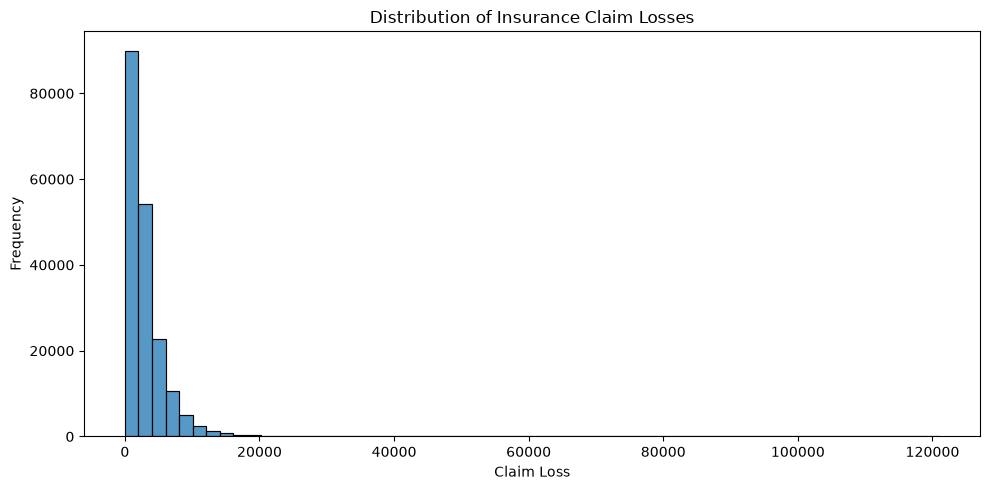

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data=train, x="loss", bins=60)

plt.title("Distribution of Insurance Claim Losses")
plt.xlabel("Claim Loss")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 4.2 Zoomed Loss Distribution

The full histogram is heavily compressed due to extreme claim values.

To better understand the distribution of typical claims, we visualize
loss values up to the 99th percentile.

This visualization excludes extreme values from the plot only;
the original dataset remains unchanged.

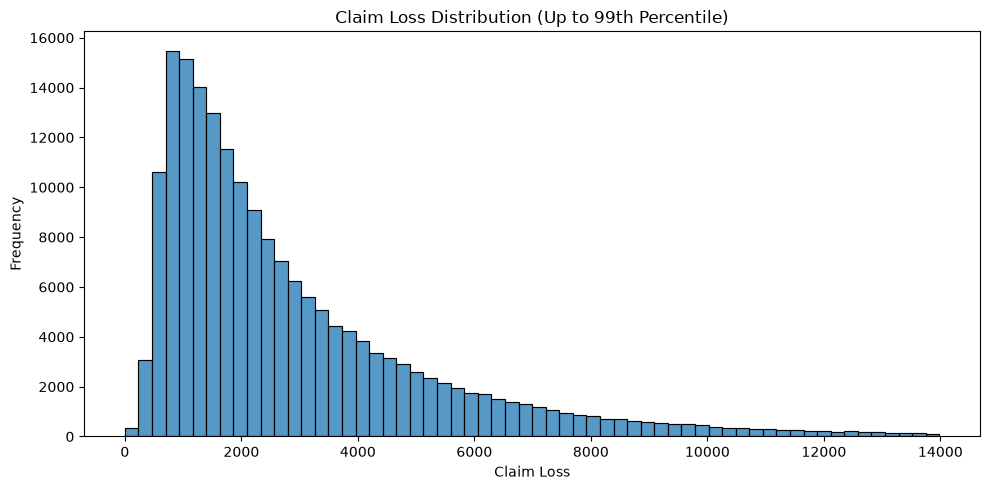

In [10]:
p99 = train["loss"].quantile(0.99)

loss_zoomed = train.loc[train["loss"] <= p99, "loss"]

plt.figure(figsize=(10, 5))

sns.histplot(loss_zoomed, bins=60)

plt.title("Claim Loss Distribution (Up to 99th Percentile)")
plt.xlabel("Claim Loss")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [11]:
print("Loss skewness:", train["loss"].skew())

Loss skewness: 3.794958377537858


### 4.3 Boxplot and Outlier Detection

We use a boxplot and the Interquartile Range (IQR) method to
investigate unusually large insurance claims.

The analysis aims to:
- Examine the spread of the middle 50% of claim losses.
- Identify observations outside the standard IQR boundaries.
- Assess whether extreme values require further investigation.

Statistical outliers will not be automatically removed.

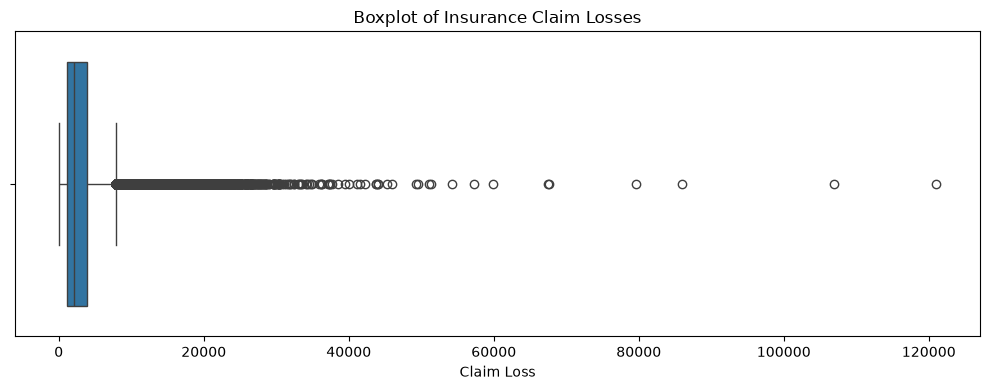

In [12]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=train["loss"])

plt.title("Boxplot of Insurance Claim Losses")
plt.xlabel("Claim Loss")

plt.tight_layout()
plt.show()

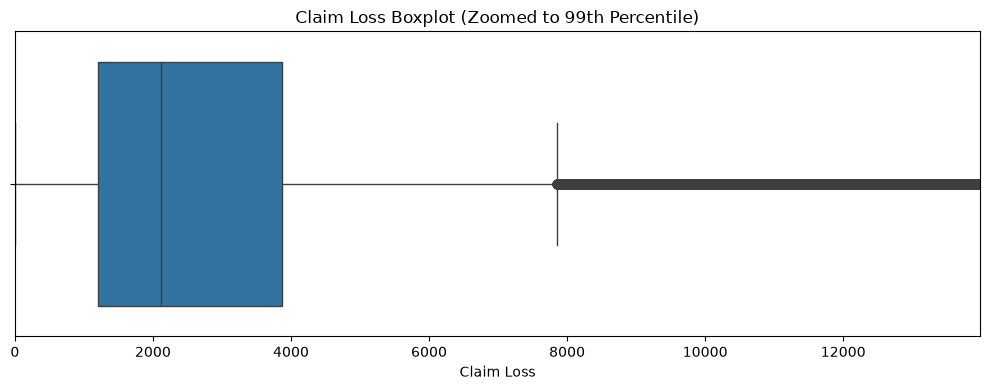

In [13]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=train["loss"])

plt.xlim(0, train["loss"].quantile(0.99))

plt.title("Claim Loss Boxplot (Zoomed to 99th Percentile)")
plt.xlabel("Claim Loss")

plt.tight_layout()
plt.show()

In [14]:
q1 = train["loss"].quantile(0.25)
q3 = train["loss"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Lower bound: ", lower_bound)
print("Upper bound: ", upper_bound)

Lower bound:  -2784.9175
Upper bound:  7853.422500000001


In [15]:
outlier_mask = (train["loss"] < lower_bound) | (train["loss"] > upper_bound)

In [16]:
outlier_mask.sum()

np.int64(11554)

In [17]:
outlier_mask.mean() * 100

np.float64(6.135366773224014)

### 4.4 Impact of High-Loss Claims

The IQR method identifies approximately 6.14% of claims as
statistical outliers.

Rather than removing these observations, we investigate their
contribution to the total claim amount and compare their
characteristics with the remaining claims.

This helps assess their business significance before making
any modeling decisions.

In [18]:
regular_losses = train.loc[~outlier_mask, "loss"]
high_losses = train.loc[outlier_mask, "loss"]

print("Regular claims mean:", regular_losses.mean())
print("High-loss claims mean:", high_losses.mean())

total_loss = train["loss"].sum()
high_loss_total = high_losses.sum()

high_loss_share = high_loss_total / total_loss * 100

print(f"High-loss share of total losses: {high_loss_share:.2f}%")

ratio = high_losses.mean() / regular_losses.mean()

print(f"High-loss claims are {ratio:.2f} times larger on average.")

Regular claims mean: 2494.6481771175127
High-loss claims mean: 11339.914134498875
High-loss share of total losses: 22.91%
High-loss claims are 4.55 times larger on average.


### 4.5 Target Analysis Findings

The target variable `loss` exhibits a strongly right-skewed distribution,
with a skewness of approximately 3.79. The mean exceeds the median,
indicating the influence of large insurance claims.

The IQR method identifies 11,554 observations (6.14%) as statistical
outliers. These claims account for approximately 22.91% of the total
claim amount and have an average loss 4.55 times that of regular claims.

**Modeling Implications:**
- Retain extreme claims unless evidence suggests data errors.
- Establish a baseline before applying target transformations.
- Evaluate prediction errors across both regular and high-loss claims.
- Compare any transformations using MAE on the original loss scale.

## 5. Numerical Feature Analysis

We explore the 14 continuous features to understand their
distributions, ranges, and variability.

This analysis will help identify unusual feature behavior
and guide subsequent correlation analysis and preprocessing.

In [19]:
cont_cols = [col for col in train.columns if col.startswith("cont")]

print("Number of continuous features:", len(cont_cols))
print("Features:", cont_cols)

Number of continuous features: 14
Features: ['cont1', 'cont2', 'cont3', 'cont4', 'cont5', 'cont6', 'cont7', 'cont8', 'cont9', 'cont10', 'cont11', 'cont12', 'cont13', 'cont14']


In [20]:
train[cont_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
cont1,188318.0,0.493861,0.187640,0.000016,0.346090,0.475784,0.623912,0.984975
cont2,188318.0,0.507188,0.207202,0.001149,0.358319,0.555782,0.681761,0.862654
cont3,188318.0,0.498918,0.202105,0.002634,0.336963,0.527991,0.634224,0.944251
cont4,188318.0,0.491812,0.211292,0.176921,0.327354,0.452887,0.652072,0.954297
cont5,188318.0,0.487428,0.209027,0.281143,0.281143,0.422268,0.643315,0.983674
cont6,188318.0,0.490945,0.205273,0.012683,0.336105,0.440945,0.655021,0.997162
cont7,188318.0,0.484970,0.178450,0.069503,0.350175,0.438285,0.591045,1.000000
cont8,188318.0,0.486437,0.199370,0.236880,0.312800,0.441060,0.623580,0.980200
cont9,188318.0,0.485506,0.181660,0.000080,0.358970,0.441450,0.566820,0.995400
cont10,188318.0,0.498066,0.185877,0.000000,0.364580,0.461190,0.614590,0.994980


### 5.1 Numerical Feature Distributions

Although the continuous features have similar means and values
within the [0, 1] range, their distributions may differ.

We visualize each feature to examine its shape, concentration,
and variability before investigating relationships with the target.

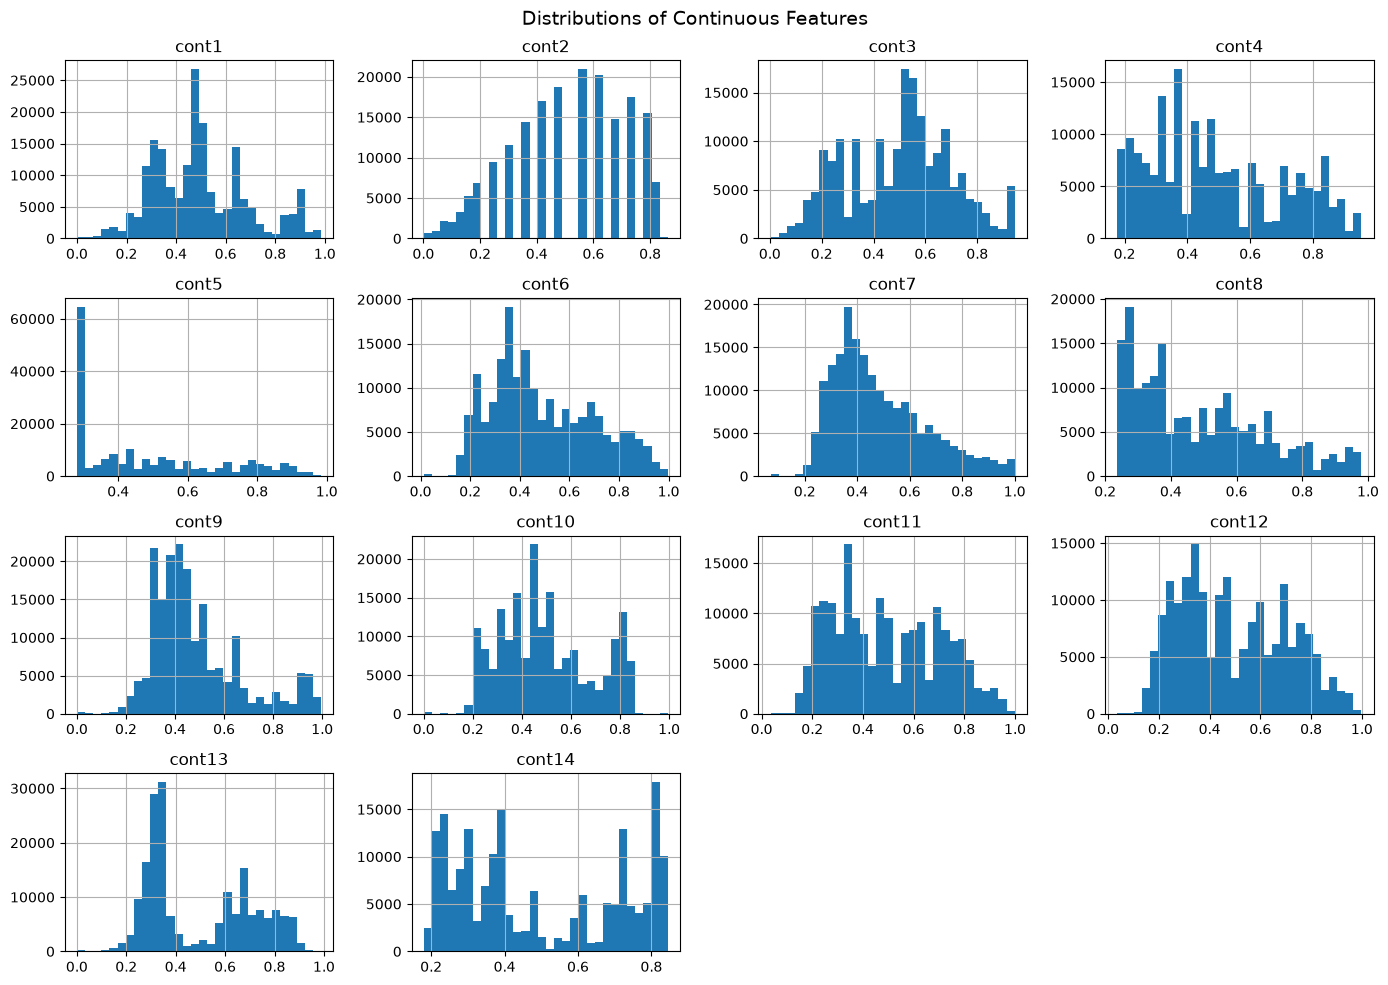

In [21]:
train[cont_cols].hist(bins=30, figsize=(14, 10), layout=(4, 4))

plt.suptitle("Distributions of Continuous Features", fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
feature_skewness = train[cont_cols].skew().sort_values()
display(feature_skewness)

cont2    -0.310941
cont3    -0.010002
cont14    0.248674
cont11    0.280821
cont12    0.291992
cont10    0.355001
cont13    0.380742
cont4     0.416096
cont6     0.461214
cont1     0.516424
cont8     0.676634
cont5     0.681622
cont7     0.826053
cont9     1.072429
dtype: float64

In [23]:
for col in ["cont5", "cont9", "cont14"]:
    print(f"\n{col}")
    print("Unique values:", train[col].nunique())
    display(train[col].value_counts().head())


cont5
Unique values: 141


cont5
0.281143    51926
0.422268     9010
0.302678     7840
0.372405     4657
0.594196     3719
Name: count, dtype: int64


cont9
Unique values: 347


cont9
0.38249    8850
0.44352    6927
0.30859    6657
0.32128    5962
0.41471    5293
Name: count, dtype: int64


cont14
Unique values: 18740


cont14
0.297706    177
0.740079    174
0.297137    154
0.229440    151
0.229429    149
Name: count, dtype: int64

### 5.1 Numerical Distribution Findings

The continuous features have similar means and values within
the [0, 1] range, but their distributions differ considerably.

Key observations:
- `cont9` has the highest positive skewness (1.072).
- `cont2` has the most negative skewness (-0.311).
- `cont5` contains a highly frequent value, appearing in approximately 27.6% of records.
- `cont14` exhibits multiple peaks despite relatively low skewness.

These findings suggest heterogeneous feature distributions.
Further analysis is needed to assess their predictive relationships.

### 5.2 Feature-Target Correlation

We examine the linear relationships between continuous features
and the target variable using Pearson correlation.

This analysis helps identify potentially informative features
and provides an initial understanding of feature relevance.

Correlation alone does not establish causality or predictive importance.

In [24]:
target_corr = (
    train[cont_cols + ["loss"]]
    .corr(method="pearson")["loss"]
    .drop("loss")
    .sort_values(ascending=False)
)

display(target_corr)

cont2     0.141528
cont7     0.119799
cont3     0.111053
cont11    0.099806
cont12    0.098724
cont6     0.040967
cont8     0.030508
cont10    0.020236
cont14    0.019298
cont9     0.014456
cont13   -0.004022
cont1    -0.010237
cont5    -0.011355
cont4    -0.035831
Name: loss, dtype: float64

### 5.3 Pearson vs. Spearman Correlation

We compare Pearson and Spearman correlations to examine
linear and monotonic relationships between continuous
features and claim severity.

Since the target distribution is highly skewed, Spearman
correlation may provide additional insights into feature
relationships that Pearson correlation alone cannot capture.

In [25]:
corr_comparison = pd.DataFrame(
    {
        "Pearson": train[cont_cols].corrwith(train["loss"], method="pearson"),
        "Spearman": train[cont_cols].corrwith(train["loss"], method="spearman"),
    }
)

display(corr_comparison.round(3))

,Pearson,Spearman
cont1,-0.010,-0.018
cont2,0.142,0.080
cont3,0.111,0.068
cont4,-0.036,-0.028
cont5,-0.011,-0.015
cont6,0.041,0.020
cont7,0.120,0.055
cont8,0.031,0.027
cont9,0.014,0.004
cont10,0.020,0.003


In [26]:
corr_comparison["difference"] = (
    corr_comparison["Pearson"] - corr_comparison["Spearman"]
).abs()

largest_gap_feature = corr_comparison["difference"].idxmax()

print("Largest difference:", largest_gap_feature)
print("Difference:", corr_comparison.loc[largest_gap_feature, "difference"])

Largest difference: cont7
Difference: 0.06487136640731464


### 5.4 Numerical Feature Analysis Findings

The 14 continuous features have similar means and values within
the [0, 1] range, but their distributions vary considerably.

Key findings:
- `cont9` has the highest positive skewness (1.072).
- `cont5` contains a highly frequent value, accounting for approximately 27.6% of observations.
- `cont2` has the strongest positive correlation with `loss` under both Pearson (0.142) and Spearman (0.080).
- `cont7` shows the largest absolute difference between Pearson and Spearman correlations (approximately 0.065).

Overall, the feature-target correlations are weak. However, weak
individual correlations do not rule out nonlinear relationships
or useful feature interactions.

**Decision:** Retain all continuous features for initial modeling
and assess their predictive value using validation results.

## 6. Categorical Feature Analysis

The dataset contains 116 categorical features that require
further exploration before encoding and modeling.

We will examine category cardinality, frequency distributions,
and rare categories to understand their structure and
potential preprocessing requirements.

In [27]:
cat_cols = [col for col in train.columns if col.startswith("cat")]

cat_cardinality = train[cat_cols].nunique().sort_values()

print("number of categorical features: ", len(cat_cols))

display(cat_cardinality)

number of categorical features:  116


cat1        2
cat52       2
cat51       2
cat50       2
cat49       2
         ... 
cat112     51
cat113     61
cat109     84
cat110    131
cat116    326
Length: 116, dtype: int64

In [28]:
print("Original categorical columns:", len(cat_cols))

print("Columns after standard one-hot encoding:", cat_cardinality.sum())

Original categorical columns: 116
Columns after standard one-hot encoding: 1139


### 6.1 Category Frequency Analysis

Categorical features differ in both cardinality and category frequency.

We examine the frequency distribution of high-cardinality features
to identify dominant and rare categories.

These findings will help guide future encoding decisions.

In [29]:
category_counts = train["cat116"].value_counts()

print("Most frequent categories:")
display(category_counts.head(10))

print("Least frequent categories:")
display(category_counts.tail(10))

Most frequent categories:


cat116
HK    21061
DJ    20244
CK    10162
DP     9202
GS     8736
CR     6862
HX     5629
DC     4557
HG     4414
IE     4225
Name: count, dtype: int64

Least frequent categories:


cat116
MH    1
MT    1
FO    1
JI    1
FQ    1
FN    1
BB    1
HU    1
IX    1
AE    1
Name: count, dtype: int64

In [30]:
category_percentage = train["cat116"].value_counts(normalize=True) * 100

display(category_percentage.head(10))

cat116
HK    11.183742
DJ    10.749902
CK     5.396192
DP     4.886416
GS     4.638962
CR     3.643836
HX     2.989093
DC     2.419843
HG     2.343908
IE     2.243545
Name: proportion, dtype: float64

### 6.2 Rare Category Analysis

We investigate the prevalence of rare categories in high-cardinality
features, focusing initially on `cat116`.

Categories appearing 10 times or fewer are considered rare for
exploratory purposes. This threshold is not a final preprocessing
decision.

We examine both the number of rare categories and the proportion
of records they represent.

In [31]:
rare_mask = category_counts <= 10


rare_category_count = rare_mask.sum()
rare_category_pct = rare_category_count / len(category_counts) * 100


rare_record_count = category_counts[rare_mask].sum()
rare_record_pct = rare_record_count / len(train) * 100

print(f"Rare categories: {rare_category_count}")
print(f"Rare category percentage: {rare_category_pct:.2f}%")
print(f"Records in rare categories: {rare_record_count}")
print(f"Rare record percentage: {rare_record_pct:.2f}%")

Rare categories: 119
Rare category percentage: 36.50%
Records in rare categories: 372
Rare record percentage: 0.20%


### Rare Category Findings

The `cat116` feature contains 326 unique categories, of which
119 (36.50%) appear 10 times or fewer.

Despite representing a substantial proportion of categories,
these rare values account for only 372 records (0.20% of training data).

Rare-category grouping may reduce encoding complexity, but its
impact on predictive performance must be evaluated before adoption.

### 6.3 Unseen Categories in Test Data

We compare categorical values between the training and test datasets
to identify categories that appear only in the test set.

This analysis helps anticipate encoding challenges and ensures
that preprocessing can handle previously unseen categories.

In [32]:
train_categories = set(train["cat116"])
test_categories = set(test["cat116"])

unseen_categories = test_categories - train_categories

print("Number of unseen categories:", len(unseen_categories))
print("Unseen categories:", sorted(unseen_categories))

Number of unseen categories: 23
Unseen categories: ['A', 'AI', 'AQ', 'BE', 'BH', 'BJ', 'BN', 'BR', 'DB', 'EM', 'ER', 'ET', 'EX', 'FY', 'HS', 'IS', 'IW', 'JS', 'KO', 'LP', 'LS', 'MX', 'N']


In [33]:
test_records_in_unseen = test["cat116"].isin(unseen_categories).sum()

test_record_ratio = (test_records_in_unseen / len(test)) * 100

print(f"Unseen records: {test_records_in_unseen}")
print(f"Unseen record percentage: {test_record_ratio:.2f}%")

Unseen records: 28
Unseen record percentage: 0.02%


### Unseen Category Findings

The `cat116` feature contains 23 categories in the test set
that are absent from the training set.

These unseen categories affect only 28 test records (0.02%),
suggesting limited exposure for this feature.

However, encoding methods must still handle unseen categories.
The same analysis will be extended to all categorical features.


### 6.4 Unseen Categories Across All Categorical Features

The previous analysis identified unseen categories in `cat116`.
However, similar differences may exist in other categorical features.

We extend this analysis to all categorical columns to:
- Identify features containing unseen test categories.
- Measure the number of affected test records.
- Assess the overall prevalence of unseen categorical values.

These findings will inform future encoding decisions.
No preprocessing transformations are applied at this stage.


In [34]:
unseen_results = []
rows_with_unseen = pd.Series(False, index=test.index)

for col in cat_cols:
    unseen_mask = ~test[col].isin(train[col].unique())

    rows_with_unseen |= unseen_mask

    unseen_results.append(
        {
            "feature": col,
            "unseen_categories": test.loc[unseen_mask, col].nunique(),
            "affected_records": unseen_mask.sum(),
            "affected_pct": unseen_mask.mean() * 100,
        }
    )

unseen_summary = pd.DataFrame(unseen_results)

affected_features = unseen_summary[unseen_summary["unseen_categories"] > 0].sort_values(
    "affected_records", ascending=False
)

display(affected_features.round(3))

print("Features with unseen categories:", len(affected_features))
print("Test records with any unseen category:", rows_with_unseen.sum())
print(f"Affected test records: {rows_with_unseen.mean():.2%}")

,feature,unseen_categories,affected_records,affected_pct
115,cat116,23,28,0.022
91,cat92,2,3,0.002
109,cat110,3,3,0.002
88,cat89,1,2,0.002
108,cat109,1,2,0.002
112,cat113,2,2,0.002
95,cat96,1,1,0.001
98,cat99,1,1,0.001
102,cat103,1,1,0.001
105,cat106,1,1,0.001


Features with unseen categories: 11
Test records with any unseen category: 42
Affected test records: 0.03%



### 6.4 Unseen Category Findings

Across the 116 categorical features, 11 contain categories
in the test set that are absent from the training set.

The `cat116` feature has the highest number of unseen
categories (23), affecting 28 test records.

Overall, 42 unique test records (0.03%) contain at least
one unseen categorical value.

**Modeling Implications:**
- Use encoding methods that can handle unknown categories.
- Retain categorical features for initial modeling.
- Evaluate rare-category grouping based on validation performance.

Given the limited number of affected records, no categories
or features are removed at this stage.



## 7. Data Understanding Summary

The initial analysis provides several insights into the dataset
and its implications for predictive modeling.

**Key Findings:**
- No missing values or duplicate records were identified.
- The target variable is strongly right-skewed, with influential high-loss claims.
- Continuous features show diverse distributions and generally weak individual correlations with the target.
- Categorical features vary in cardinality and contain rare categories.
- Unseen test categories affect only 42 records (0.03%).

**Next Steps:**
- Establish a reproducible train-validation split.
- Build a simple baseline using Mean Absolute Error (MAE).
- Implement preprocessing that handles unseen categories.
- Evaluate more advanced models against the baseline.

The initial modeling stage will retain all predictive features
and use validation results to guide further improvements.
